In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/train.csv")

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [8]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [19]:
df['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [27]:
df['Sex'].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

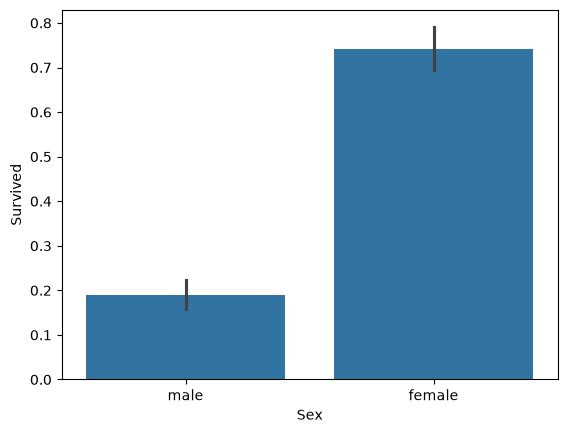

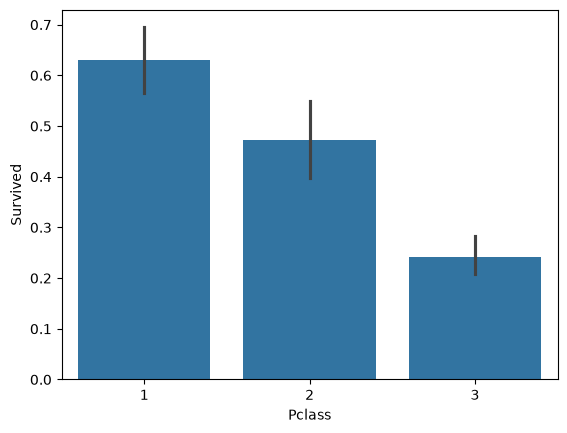

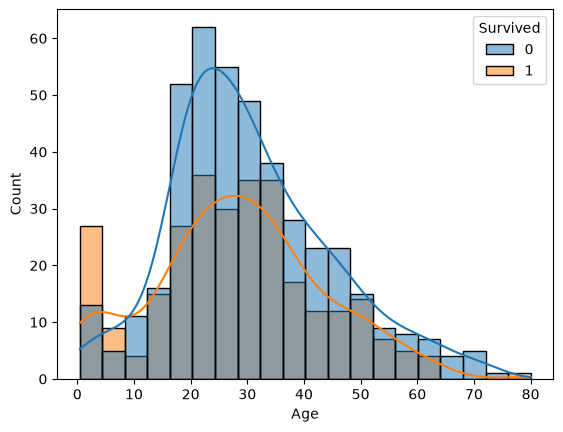

In [38]:
sns.barplot(data=df, x="Sex", y="Survived")
plt.show()

sns.barplot(data=df, x="Pclass", y="Survived")
plt.show()

sns.histplot(data=df, x="Age", hue="Survived", kde=True)
plt.show()

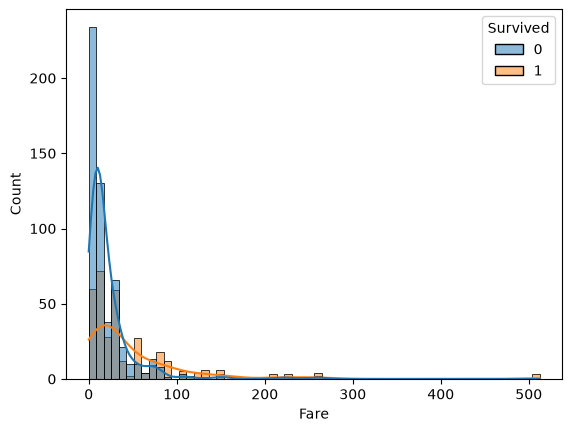

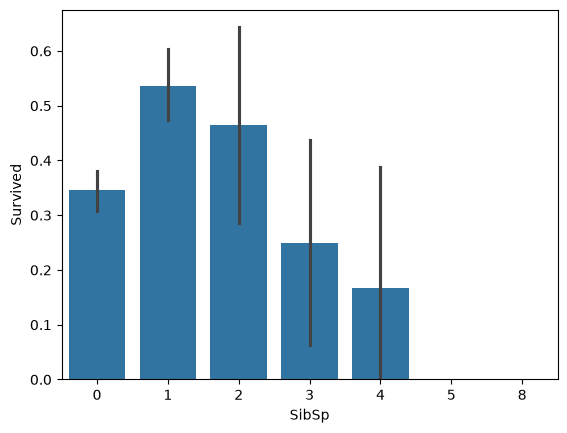

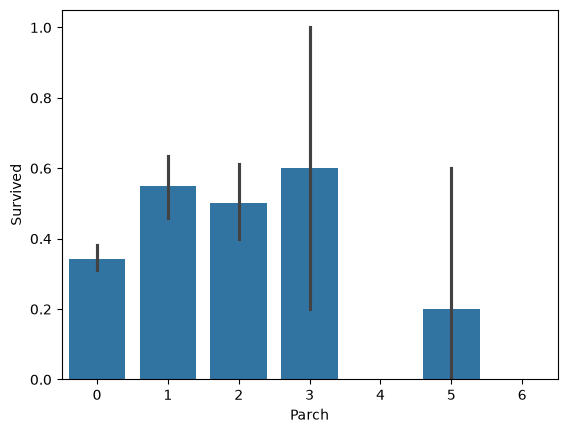

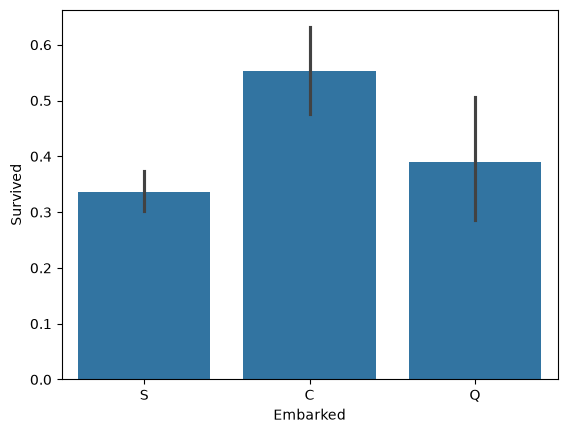

In [40]:
sns.histplot(data=df, x="Fare", hue="Survived", kde=True)
plt.show()

sns.barplot(data=df, x="SibSp", y="Survived")
plt.show()

sns.barplot(data=df, x="Parch", y="Survived")
plt.show()

sns.barplot(data=df, x="Embarked", y="Survived")
plt.show()

In [41]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [42]:
df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

In [43]:
df["Age"] = df["Age"].fillna(df["Age"].median())

In [44]:
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [45]:
df.isnull().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

In [46]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [47]:
df = pd.get_dummies(df, columns=["Sex", "Embarked"], drop_first=True)

In [48]:
df.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,35.0,0,0,8.0500,True,False,True


In [49]:
X = df.drop(columns=["Survived"])
y = df["Survived"]

In [50]:
print(X.shape)
print(y.shape)

(891, 8)
(891,)


In [51]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [53]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [54]:
y_pred = model.predict(X_test)

In [60]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[90 15]
 [19 55]]


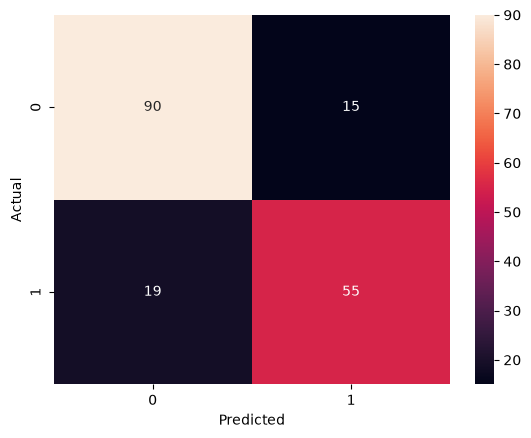

In [61]:
sns.heatmap(cm, annot=True, fmt="d")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [62]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Accuracy: 0.8100558659217877
Precision: 0.7857142857142857
Recall: 0.7432432432432432
F1 Score: 0.7638888888888888


In [63]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

In [64]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

print(confusion_matrix(y_test, y_pred_tree))
print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print("F1 Score:", f1_score(y_test, y_pred_tree))

[[84 21]
 [18 56]]
Accuracy: 0.7821229050279329
Precision: 0.7272727272727273
Recall: 0.7567567567567568
F1 Score: 0.7417218543046358


In [66]:
# for depth in [2, 3, 4, 5, 6, 8, 10]:
#     tree_model = DecisionTreeClassifier(
#         max_depth=depth,
#         random_state=42
#     )

#     tree_model.fit(X_train, y_train)
#     y_pred_tree = tree_model.predict(X_test)

#     print(depth, accuracy_score(y_test, y_pred_tree))

In [189]:
from sklearn.model_selection import cross_val_score

# tree_model = DecisionTreeClassifier(random_state=42)

# scores = cross_val_score(
#     tree_model,
#     X_train,
#     y_train,
#     cv=5,
#     scoring="accuracy"
# )

# print("Scores:", scores)
# print("Mean accuracy:", scores.mean())

In [70]:
# combo of the above two:

In [69]:
for depth in [2, 3, 4, 5, 6, 8, 10]:
    tree_model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    scores = cross_val_score(
        tree_model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    print(depth, scores.mean())

2 0.7864670540726879
3 0.8202107751403526
4 0.8033389146065202
5 0.8019698611247905
6 0.8047375160051218
8 0.7977445090121146
10 0.772461341475426


In [71]:
from sklearn.tree import DecisionTreeClassifier

tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

In [72]:
print(confusion_matrix(y_test, y_pred_tree))
print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print("F1 Score:", f1_score(y_test, y_pred_tree))

[[92 13]
 [23 51]]
Accuracy: 0.7988826815642458
Precision: 0.796875
Recall: 0.6891891891891891
F1 Score: 0.7391304347826086


In [97]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

In [98]:
print(confusion_matrix(y_test, y_pred_rf))
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

[[91 14]
 [18 56]]
Accuracy: 0.8212290502793296
Precision: 0.8
Recall: 0.7567567567567568
F1 Score: 0.7777777777777778


In [99]:
for n_est in [50, 100, 150, 200]:
    rf_model = RandomForestClassifier(
        n_estimators=n_est,
        random_state=42
    )

    scores = cross_val_score(
        rf_model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    print(n_est, scores.mean())

50 0.8048360090613611
100 0.7949867034374076
150 0.7978036048458584
200 0.7949965527430317


In [100]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=50,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

In [101]:
print(confusion_matrix(y_test, y_pred_rf))
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

[[91 14]
 [18 56]]
Accuracy: 0.8212290502793296
Precision: 0.8
Recall: 0.7567567567567568
F1 Score: 0.7777777777777778


In [139]:
# --------- new feature engineering --------------

df = pd.read_csv("../data/train.csv")

In [140]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.")

In [141]:
df[["SibSp", "Parch", "FamilySize"]].head()

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


In [142]:
df["Title"].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [143]:
rare_titles = [
    "Dr", "Rev", "Major", "Mlle", "Col", "Don",
    "Mme", "Ms", "Lady", "Sir", "Capt",
    "the Countess", "Jonkheer"
]

df["Title"] = df["Title"].replace(rare_titles, "Rare")

In [144]:
df["Title"].value_counts()

Title
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64

In [145]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

df = pd.get_dummies(
    df,
    columns=["Sex", "Embarked", "Title"],
    drop_first=True
)

In [146]:
df.isnull().sum()

Survived      0
Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
FamilySize    0
Sex_male      0
Embarked_Q    0
Embarked_S    0
Title_Miss    0
Title_Mr      0
Title_Mrs     0
Title_Rare    0
dtype: int64

In [147]:
X = df.drop(columns=["Survived"])
y = df["Survived"]

In [148]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [149]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=50,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

In [150]:
print(confusion_matrix(y_test, y_pred_rf))
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

[[90 15]
 [15 59]]
Accuracy: 0.8324022346368715
Precision: 0.7972972972972973
Recall: 0.7972972972972973
F1 Score: 0.7972972972972973


In [171]:
df = pd.read_csv("../data/train.csv")
df["Cabin"].dropna().head(20)

1             C85
3            C123
6             E46
10             G6
11           C103
21            D56
23             A6
27    C23 C25 C27
31            B78
52            D33
54            B30
55            C52
61            B28
62            C83
66            F33
75          F G73
88    C23 C25 C27
92            E31
96             A5
97        D10 D12
Name: Cabin, dtype: str

In [172]:
df["Deck"] = df["Cabin"].str[0]

In [173]:
df["Deck"].value_counts(dropna=False)

Deck
NaN    687
C       59
B       47
D       33
E       32
A       15
F       13
G        4
T        1
Name: count, dtype: int64

In [174]:
df["Deck"] = df["Deck"].fillna("Unknown")
df["Deck"].value_counts()

Deck
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64

In [175]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

df["Title"] = df["Name"].str.extract(r",\s*([^.]*)\.")

rare_titles = [
    "Dr", "Rev", "Major", "Mlle", "Col", "Don",
    "Mme", "Ms", "Lady", "Sir", "Capt",
    "the Countess", "Jonkheer"
]

df["Title"] = df["Title"].replace(rare_titles, "Rare")

df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

df = df.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

df = pd.get_dummies(
    df,
    columns=["Sex", "Embarked", "Title", "Deck"],
    drop_first=True
)

In [176]:
df.isnull().sum()

Survived        0
Pclass          0
Age             0
SibSp           0
Parch           0
Fare            0
FamilySize      0
Sex_male        0
Embarked_Q      0
Embarked_S      0
Title_Miss      0
Title_Mr        0
Title_Mrs       0
Title_Rare      0
Deck_B          0
Deck_C          0
Deck_D          0
Deck_E          0
Deck_F          0
Deck_G          0
Deck_T          0
Deck_Unknown    0
dtype: int64

In [177]:
X = df.drop(columns=["Survived"])
y = df["Survived"]

In [178]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [179]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=50,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

In [180]:
print(confusion_matrix(y_test, y_pred_rf))
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

[[87 18]
 [16 58]]
Accuracy: 0.8100558659217877
Precision: 0.7631578947368421
Recall: 0.7837837837837838
F1 Score: 0.7733333333333333


In [181]:
deck_columns = [col for col in X.columns if col.startswith("Deck_")]

X = X.drop(columns=deck_columns)

In [182]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [183]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=50,
    random_state=42
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

In [184]:
print(confusion_matrix(y_test, y_pred_rf))
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))

[[90 15]
 [15 59]]
Accuracy: 0.8324022346368715
Precision: 0.7972972972972973
Recall: 0.7972972972972973
F1 Score: 0.7972972972972973


In [185]:
import pandas as pd

importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
)

print(importance.sort_values(ascending=False))

Fare          0.238105
Age           0.219434
Sex_male      0.147221
Title_Mr      0.117821
Pclass        0.070931
FamilySize    0.051859
SibSp         0.041150
Title_Mrs     0.027926
Embarked_S    0.023979
Parch         0.022095
Title_Miss    0.021824
Embarked_Q    0.010602
Title_Rare    0.007054
dtype: float64


In [190]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [2, 3, 4, 5, 6, 8, 10, None]
}

rf_model = RandomForestClassifier(random_state=42)

grid_search = GridSearchCV(
    rf_model,
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid_search.fit(X_train, y_train)

print(grid_search.best_params_)
print(grid_search.best_score_)

{'max_depth': 6, 'n_estimators': 200}
0.8342164877376146


In [192]:
best_rf = grid_search.best_estimator_

y_pred = best_rf.predict(X_test)

In [197]:
print(confusion_matrix(y_test, y_pred))
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

[[93 12]
 [19 55]]
Accuracy: 0.8268156424581006
Precision: 0.8208955223880597
Recall: 0.7432432432432432
F1 Score: 0.7801418439716312


In [198]:
#------ gradientboosting -------

In [200]:
from sklearn.ensemble import GradientBoostingClassifier

In [201]:
gb_model = GradientBoostingClassifier(random_state=42)

In [202]:
gb_model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [203]:
y_pred_gb = gb_model.predict(X_test)

In [204]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print(confusion_matrix(y_test, y_pred_gb))
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:", f1_score(y_test, y_pred_gb))

[[92 13]
 [21 53]]
Accuracy: 0.8100558659217877
Precision: 0.803030303030303
Recall: 0.7162162162162162
F1 Score: 0.7571428571428571


In [206]:
param_grid = {
    "n_estimators": [50, 100, 150, 200],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [2, 3, 4, 5]
}

gb_model = GradientBoostingClassifier(random_state=42)

grid_search_gb = GridSearchCV(
    gb_model,
    param_grid,
    cv=5,
    scoring="accuracy"
)

grid_search_gb.fit(X_train, y_train)

print(grid_search_gb.best_params_)
print(grid_search_gb.best_score_)

{'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 200}
0.8300206835418102


In [207]:
best_gb = grid_search_gb.best_estimator_

y_pred_gb = best_gb.predict(X_test)

In [209]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print(confusion_matrix(y_test, y_pred_gb))
print("Accuracy:", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall:", recall_score(y_test, y_pred_gb))
print("F1 Score:", f1_score(y_test, y_pred_gb))

[[93 12]
 [19 55]]
Accuracy: 0.8268156424581006
Precision: 0.8208955223880597
Recall: 0.7432432432432432
F1 Score: 0.7801418439716312


In [211]:
test_df = pd.read_csv("../data/test.csv")

test_df.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [215]:
# Reload both datasets from the original CSVs
train_df = pd.read_csv("../data/train.csv")
test_df = pd.read_csv("../data/test.csv")

# Create Title
test_df["Title"] = test_df["Name"].str.extract(r",\s*([^.]*)\.")

# Group rare titles
rare_titles = [
    "Dr", "Rev", "Major", "Mlle", "Col", "Don",
    "Mme", "Ms", "Lady", "Sir", "Capt",
    "the Countess", "Jonkheer"
]

test_df["Title"] = test_df["Title"].replace(rare_titles, "Rare")

# Create FamilySize
test_df["FamilySize"] = test_df["SibSp"] + test_df["Parch"] + 1

# Fill missing values using TRAINING data statistics
test_df["Age"] = test_df["Age"].fillna(train_df["Age"].median())
test_df["Fare"] = test_df["Fare"].fillna(train_df["Fare"].median())
test_df["Embarked"] = test_df["Embarked"].fillna(train_df["Embarked"].mode()[0])

# Keep PassengerId separately for the final submission
passenger_ids = test_df["PassengerId"]

# Remove columns we don't use as model features
test_df = test_df.drop(
    columns=["PassengerId", "Name", "Ticket", "Cabin"]
)

In [216]:
test_df.isnull().sum()

Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      0
Title         0
FamilySize    0
dtype: int64

In [217]:
test_df = pd.get_dummies(
    test_df,
    columns=["Sex", "Embarked", "Title"],
    drop_first=True
)

In [218]:
print(test_df.columns)

Index(['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'Sex_male',
       'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr',
       'Title_Mrs', 'Title_Rare'],
      dtype='str')


In [219]:
test_df = test_df.reindex(columns=X.columns, fill_value=0)

In [220]:
print(test_df.columns)
print(X.columns)

Index(['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'Sex_male',
       'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs',
       'Title_Rare'],
      dtype='str')
Index(['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'Sex_male',
       'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs',
       'Title_Rare'],
      dtype='str')


In [221]:
y_test_pred = best_rf.predict(test_df)

In [222]:
print(y_test_pred[:20])
print(len(y_test_pred))

[0 0 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 0 1]
418


In [223]:
submission = pd.DataFrame({
    "PassengerId": passenger_ids,
    "Survived": y_test_pred
})

submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


In [224]:
print(submission.shape)
print(submission["Survived"].value_counts())

(418, 2)
Survived
0    273
1    145
Name: count, dtype: int64


In [227]:
submission.to_csv("../submission.csv", index=False)

In [229]:
pd.read_csv("../submission.csv").head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
